# P05 GEO-SOM 결함 재현 (회기동 규모, Colab 실행본)

- 판정 임계값은 **실행 전에 정해** 아래 판정 함수(`verdict_a`, `verdict_b` 등)에 고정했고, 결과를 본 뒤 바꾸지 않았습니다. 이 노트북은 그 기준을 코드로 옮긴 것입니다.
- 위에서 아래로 순서대로 실행합니다. 학습 1회가 Colab에서 약 1~2분이고 전체(12회) 약 15~25분입니다.
- 원본 코드는 `utils.py`를 그대로 씁니다(셀 3에서 파일로 씀). 수정본(`GeoSOMFixed`)만 이 노트북에 새로 있습니다.
- 이 파일은 실제 실행 출력(표·그림)이 포함된 실행본입니다. 서울 전체가 아니라 회기동(건물 783개) 규모 결과입니다.
- 데이터 zip 2개는 `data/hoegiDong.zip`(이 레포)과 동대문구 건물 데이터(`AL_D198_11230_...zip`, 레포에는 용량 때문에 없음)입니다.

## 1. 준비

In [1]:
import geopandas, sklearn, numpy, pandas, scipy
print('geopandas', geopandas.__version__, '| sklearn', sklearn.__version__, '| numpy', numpy.__version__, '| pandas', pandas.__version__)

geopandas 1.2.0 | sklearn 1.6.1 | numpy 2.4.6 | pandas 2.2.3


In [2]:
# 데이터 zip 2개를 올린다 (건물 zip 141MB는 시간이 좀 걸린다). 이미 /content에 있으면 건너뛴다.
import glob, os, zipfile
if not glob.glob('/content/AL_D198*.zip') or not glob.glob('/content/hoegiDong*.zip'):
    from google.colab import files
    files.upload()
for z in glob.glob('/content/AL_D198*.zip') + glob.glob('/content/hoegiDong*.zip'):
    zipfile.ZipFile(z).extractall('/content/data')
print(glob.glob('/content/data/**/*.shp', recursive=True))

Saving AL_D198_11230_20250115-20250603T121458Z-1-001.zip to AL_D198_11230_20250115-20250603T121458Z-1-001.zip
Saving hoegiDong-20250603T121531Z-1-001.zip to hoegiDong-20250603T121531Z-1-001.zip
['/content/data/AL_D198_11230_20250115/AL_D198_11230_20250115.shp', '/content/data/hoegiDong/hoegi.shp']


In [3]:
%%writefile utils.py
import geopandas as gpd
import pandas as pd
import numpy as np
from scipy.spatial import distance_matrix
from shapely.geometry import Polygon, box, LineString
import matplotlib.pyplot as plt
from shapely.geometry import Point, Polygon, MultiPoint
from scipy.spatial import Voronoi
from tqdm import tqdm  # tqdm 추가
import os


import time
import hashlib
import scipy
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, Birch
from sklearn.datasets import make_blobs


def construct_voronoi_polygons(X_geo, extend_distance=None):
    vor = Voronoi(X_geo)

    center = vor.points.mean(axis=0)
    if extend_distance is None:
        extend_distance = np.ptp(vor.points, axis=0).max() * 2 # 데이터 범위의 2배로 연장

    all_ridges = {}
    for (p1, p2), (v1, v2) in zip(vor.ridge_points, vor.ridge_vertices):
        all_ridges.setdefault(p1, []).append((p2, v1, v2))
        all_ridges.setdefault(p2, []).append((p1, v1, v2))

    polygons = []

    for p_idx, region_idx in enumerate(vor.point_region):
        vertices = vor.regions[region_idx]
        if -1 not in vertices:
            # 유한한 영역 -> 바로 Polygon 생성
            poly_points = [vor.vertices[v] for v in vertices]
            polygons.append(Polygon(poly_points))
        else:
            # 무한한 영역 -> 보완이 필요
            ridge_segments = []
            ridges = all_ridges[p_idx]
            for p2, v1, v2 in ridges:
                v1, v2 = np.asarray(v1), np.asarray(v2)
                if v1 >= 0 and v2 >= 0:
                    # 유한한 에지
                    ridge_segments.append(vor.vertices[[v1, v2]])
                else:
                    # 무한한 에지
                    if v1 == -1:
                        v = v2
                    else:
                        v = v1
                    tangent = vor.points[p2] - vor.points[p_idx]
                    tangent = tangent / np.linalg.norm(tangent)
                    normal = np.array([-tangent[1], tangent[0]])

                    if np.dot(normal, vor.vertices[v] - center) < 0:
                        normal = -normal

                    far_point = vor.vertices[v] + normal * extend_distance
                    ridge_segments.append(np.vstack([vor.vertices[v], far_point]))

            # 이 모든 선분들의 꼭짓점을 연결
            poly_points = []
            for seg in ridge_segments:
                poly_points.append(seg[0])
                poly_points.append(seg[1])
            poly = Polygon(poly_points)
            polygons.append(poly.convex_hull)  # Convex Hull로 정리해서 Polygon 생성

    return polygons, vor


# ====== Geo-SOM Class ======
class GeoSOM:
    def __init__(self, grid_shape, geo_tolerance, input_dim, learning_rate=0.01, radius=2, fixed_geo=False):
        self.grid_shape = grid_shape
        self.geo_tolerance = geo_tolerance
        self.input_dim = input_dim  # X_ngf.shape[1] 대신 직접 받도록 수정
        self.learning_rate = learning_rate
        self.radius = radius
        self.fixed_geo = fixed_geo
        self.init_map()

    def init_map(self):
        rows, cols = self.grid_shape
        self.map_geo = np.array([[(i, j) for j in range(cols)] for i in range(rows)], dtype=np.float64).reshape(-1, 2)
        self.map_ngf = np.random.rand(rows * cols, self.input_dim)

    def train(self, X_geo, X_ngf, epochs=100):
        for epoch in tqdm(range(epochs), desc="Training GeoSOM"):  # tqdm 적용
            alpha = self.learning_rate * (1 - epoch / epochs)
            radius = self.radius * (1 - epoch / epochs)
            for i in range(len(X_geo)):
                x_geo = X_geo[i]
                x_ngf = X_ngf[i]
                dists_geo = np.linalg.norm(self.map_geo - x_geo, axis=1)
                geo_winner_idx = np.argmin(dists_geo)
                geo_winner_pos = self.map_geo[geo_winner_idx]
                neighborhood_idx = [j for j, unit_pos in enumerate(self.map_geo)
                                    if np.linalg.norm(geo_winner_pos - unit_pos) <= self.geo_tolerance]

                bmu_idx = min(neighborhood_idx,
                              key=lambda j: np.linalg.norm(x_ngf - self.map_ngf[j]))

                for j in neighborhood_idx:
                    dist_output = np.linalg.norm(self.map_geo[bmu_idx] - self.map_geo[j])
                    if dist_output <= radius:
                        h = np.exp(-(dist_output ** 2) / (2 * (radius ** 2)))
                        if self.fixed_geo:
                            self.map_ngf[j] += alpha * h * (x_ngf - self.map_ngf[j])
                        else:
                            combined_input = np.concatenate([x_geo, x_ngf])
                            combined_weight = np.concatenate([self.map_geo[j], self.map_ngf[j]])
                            delta = alpha * h * (combined_input - combined_weight)
                            self.map_geo[j] += delta[:2]
                            self.map_ngf[j] += delta[2:]


    def get_cluster_assignments(self, X_geo, X_ngf):
        assignments = []
        for i in range(len(X_geo)):
            x_geo = X_geo[i]
            x_ngf = X_ngf[i]
            dists_geo = np.linalg.norm(self.map_geo - x_geo, axis=1)
            geo_winner_idx = np.argmin(dists_geo)
            geo_winner_pos = self.map_geo[geo_winner_idx]
            neighborhood_idx = [j for j, unit_pos in enumerate(self.map_geo)
                                if np.linalg.norm(geo_winner_pos - unit_pos) <= self.geo_tolerance]
            bmu_idx = min(neighborhood_idx, key=lambda j: np.linalg.norm(x_ngf - self.map_ngf[j]))
            assignments.append(bmu_idx)
        return np.array(assignments)


# https://www.kaggle.com/code/mallikarjunaj/gap-statistics

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

def optimalK(data, maxClusters):
    """
    Calculates KMeans optimal K using Gap Statistic from Tibshirani, Walther, Hastie

    Params:
        data: ndarray of shape (n_samples, n_features)
        maxClusters: Maximum number of clusters to test for

    Returns: (optimal_k, resultsdf)
    """
    nrefs = 3
    gaps = np.zeros((len(range(1, maxClusters)),))
    resultsdf = pd.DataFrame(columns=['clusterCount', 'gap'])

    for gap_index, k in enumerate(range(1, maxClusters)):
        # 기준선 분산값 저장
        refDisps = np.zeros(nrefs)

        # nrefs개 기준선 데이터에 대해 KMeans
        for i in range(nrefs):
            randomReference = np.random.random_sample(size=data.shape)
            km = KMeans(n_clusters=k, n_init=10)
            km.fit(randomReference)
            refDisps[i] = km.inertia_

        # 실제 데이터에 대해 KMeans
        km = KMeans(n_clusters=k, n_init=10)
        km.fit(data)
        origDisp = km.inertia_

        # Gap 통계량 계산
        gap = np.log(np.mean(refDisps)) - np.log(origDisp)
        gaps[gap_index] = gap

        # 결과 누적
        new_row = pd.DataFrame([{'clusterCount': k, 'gap': gap}])
        resultsdf = pd.concat([resultsdf, new_row], ignore_index=True)

    optimal_k = gaps.argmax() + 1  # index 0 → k=1
    return optimal_k, resultsdf




Writing utils.py


In [4]:
import sys
sys.path.insert(0, '/content')
from utils import *   # 원본 utils.py 그대로: GeoSOM, optimalK, construct_voronoi_polygons

In [5]:
# --- 원 노트북 셀 7~19: 데이터 불러오기, 좌표계 맞추기, 회기동 clip, centroid ---
dongDea_gdf = gpd.read_file('/content/data/AL_D198_11230_20250115/AL_D198_11230_20250115.shp', encoding='euc-kr')
hoeGi_gdf = gpd.read_file('/content/data/hoegiDong/hoegi.shp', encoding='euc-kr')
dongDea_gdf = dongDea_gdf.to_crs('epsg:5179')
hoeGi_buildings = gpd.clip(dongDea_gdf, hoeGi_gdf)
hoeGi_buildings_centroid = hoeGi_buildings.copy()
hoeGi_buildings_centroid['geometry'] = hoeGi_buildings_centroid.geometry.centroid
print('동대문구', dongDea_gdf.shape, '| 회기동 건물', hoeGi_buildings.shape)

동대문구 (19541, 37) | 회기동 건물 (837, 37)


In [6]:
# --- 원 노트북 셀 22~29: 전처리 (MinMax 뒤에 Standard를 연속 적용한 것까지 원본 그대로) ---
hoeGi_point = hoeGi_buildings_centroid.loc[:,['A20','A21','A30','A31','A32','A34','geometry']]
hoeGi_point['total_floor'] = hoeGi_point['A31'] + hoeGi_point['A32']
hoeGi_point = hoeGi_point.loc[:,['A20','A21','A30','A34','total_floor','geometry']]
hoeGi_point.dropna(inplace=True)
for idx, row in hoeGi_point.iterrows():
    x = int(row.values[3][:4])
    if x < 1970:
        hoeGi_point.at[idx,'A34'] = '1970-01-01'
hoeGi_point.dropna(inplace=True)
hoeGi_point['A34'] = pd.to_datetime(hoeGi_point['A34'])
reference_date = pd.to_datetime('2025-01-01')
hoeGi_point['years_old'] = (reference_date - hoeGi_point['A34']).dt.days // 365
hoeGi_point.drop(columns=['A34'], inplace=True)
from sklearn.preprocessing import MinMaxScaler, StandardScaler
cols = ['A20','A21','A30','total_floor','years_old']
hoeGi_point[cols] = MinMaxScaler().fit_transform(hoeGi_point[cols])
hoeGi_point[cols] = StandardScaler().fit_transform(hoeGi_point[cols])

X_geo = np.array(hoeGi_point.geometry.apply(lambda g: [g.x, g.y]).tolist())
X_ngf = hoeGi_point[cols].values
N = len(X_geo)
print('N =', N, '| X_geo 범위(m):', X_geo.min(0), X_geo.max(0), '| X_ngf', X_ngf.shape)

N = 783 | X_geo 범위(m): [ 960049.0099093  1954396.13440782] [ 960856.44224249 1955692.78798761] | X_ngf (783, 5)


## 2. 수정본 모델과 지표, 기준 판정 (실행 전 고정)
- `GeoSOMFixed`: 격자 위치(`grid_pos`, 0..19)를 따로 두고 **tolerance·이웃 반경은 격자 거리**로, **지리 가중치(`map_geo`)는 데이터 좌표 bbox 격자로 초기화**. 나머지(학습 루프 구조, 승자 선택, 갱신식)는 원본과 같게 맞췄다.
- 판정 함수는 `실행 전에 정한 기준` 1~4장의 임계값 그대로.

In [7]:
from sklearn.neighbors import NearestNeighbors

class GeoSOMFixed:
    def __init__(self, grid_shape, geo_tolerance, input_dim, X_geo, learning_rate=0.01, radius=2, fixed_geo=False):
        self.grid_shape = grid_shape
        self.geo_tolerance = geo_tolerance
        self.input_dim = input_dim
        self.learning_rate = learning_rate
        self.radius = radius
        self.fixed_geo = fixed_geo
        rows, cols = grid_shape
        self.grid_pos = np.array([[(i, j) for j in range(cols)] for i in range(rows)], dtype=np.float64).reshape(-1, 2)
        xs = np.linspace(X_geo[:,0].min(), X_geo[:,0].max(), cols)
        ys = np.linspace(X_geo[:,1].min(), X_geo[:,1].max(), rows)
        self.map_geo = np.array([[(xs[j], ys[i]) for j in range(cols)] for i in range(rows)], dtype=np.float64).reshape(-1, 2)
        self.map_ngf = np.random.rand(rows * cols, input_dim)

    def _neigh(self, x_geo):
        w = np.argmin(np.linalg.norm(self.map_geo - x_geo, axis=1))
        d = np.linalg.norm(self.grid_pos - self.grid_pos[w], axis=1)   # tolerance는 격자 거리
        return w, np.where(d <= self.geo_tolerance)[0]

    def train(self, X_geo, X_ngf, epochs=100):
        for epoch in tqdm(range(epochs), desc="Training GeoSOMFixed"):
            alpha = self.learning_rate * (1 - epoch / epochs)
            radius = self.radius * (1 - epoch / epochs)
            for i in range(len(X_geo)):
                x_geo, x_ngf = X_geo[i], X_ngf[i]
                _, nb = self._neigh(x_geo)
                bmu_idx = nb[np.argmin(np.linalg.norm(self.map_ngf[nb] - x_ngf, axis=1))]
                for j in nb:
                    dist_output = np.linalg.norm(self.grid_pos[bmu_idx] - self.grid_pos[j])  # 반경도 격자 거리
                    if dist_output <= radius:
                        h = np.exp(-(dist_output ** 2) / (2 * (radius ** 2)))
                        self.map_ngf[j] += alpha * h * (x_ngf - self.map_ngf[j])
                        if not self.fixed_geo:
                            self.map_geo[j] += alpha * h * (x_geo - self.map_geo[j])

    def get_cluster_assignments(self, X_geo, X_ngf):
        out = []
        for i in range(len(X_geo)):
            _, nb = self._neigh(X_geo[i])
            out.append(nb[np.argmin(np.linalg.norm(self.map_ngf[nb] - X_ngf[i], axis=1))])
        return np.array(out)

def geo_winners(model, X_geo):
    return np.array([np.argmin(np.linalg.norm(model.map_geo - x, axis=1)) for x in X_geo])

def neigh_size_mean(model, winners):
    ref = model.grid_pos if hasattr(model, 'grid_pos') else model.map_geo   # 원본은 map_geo 거리 (원 코드 그대로)
    cache = {}
    for w in set(winners.tolist()):
        cache[w] = int((np.linalg.norm(ref - ref[w], axis=1) <= model.geo_tolerance).sum())
    return float(np.mean([cache[w] for w in winners]))

_nn_idx = NearestNeighbors(n_neighbors=6).fit(X_geo).kneighbors(X_geo)[1][:, 1:]
def cohesion_lift(labels, n_shuffle=20, seed=123):
    obs = (labels[_nn_idx] == labels[:, None]).mean()
    rng = np.random.default_rng(seed)
    base = np.mean([(rng.permutation(labels)[_nn_idx] == labels[:, None]).mean() for _ in range(n_shuffle)])
    return float(obs), float(base), float(obs / base)

RUNS = {}
def run_one(kind, fixed_geo, seed, epochs=50):
    np.random.seed(seed)
    if kind == 'orig':
        m = GeoSOM(grid_shape=(20, 20), geo_tolerance=4, input_dim=X_ngf.shape[1], fixed_geo=fixed_geo)
    else:
        m = GeoSOMFixed((20, 20), 4, X_ngf.shape[1], X_geo, fixed_geo=fixed_geo)
    m.train(X_geo, X_ngf, epochs=epochs)
    asg = m.get_cluster_assignments(X_geo, X_ngf)
    w = geo_winners(m, X_geo)
    vals, cnt = np.unique(w, return_counts=True)
    obs, base, lift = cohesion_lift(asg)
    r = dict(kind=kind, fixed_geo=fixed_geo, seed=seed, N=int(N),
             D_geo=int(len(vals)), top1=float(cnt.max() / N), top1_node=int(vals[cnt.argmax()]),
             D_bmu=int(len(np.unique(asg))), neigh_mean=neigh_size_mean(m, w),
             knn_obs=obs, knn_base=base, lift=lift)
    RUNS[(kind, fixed_geo, seed)] = dict(r=r, asg=asg, winners=w, model=m)
    return r

# ---- 기준 판정 (실행 전에 정한 기준 그대로) ----
def verdict_a(r):          # 원본용 (1장). (c)의 fixed_geo=False 원본에도 같은 표 적용
    if r['D_geo'] <= 2 or r['top1'] >= 0.90: return '결함 재현'
    if r['D_geo'] >= 20 and r['top1'] < 0.30: return '결함 아님(반증)'
    return '판정 보류'
def verdict_b(r, lift_a):  # 수정본용 (2장)
    ok = r['D_geo'] >= 100 and r['top1'] <= 0.10 and r['lift'] >= 2.0 and r['lift'] > lift_a
    return '수정 성공' if ok else '수정본 점검 필요(결론 보류)'

def show(keys):
    rows = []
    for k in keys:
        r = dict(RUNS[k]['r'])
        if r['kind'] == 'orig': r['판정'] = verdict_a(r)
        else:
            la = RUNS.get(('orig', True, r['seed']), {}).get('r', {}).get('lift', float('nan'))
            r['판정'] = verdict_b(r, la)
        rows.append(r)
    df = pd.DataFrame(rows)[['kind','fixed_geo','seed','N','D_geo','top1','top1_node','D_bmu','neigh_mean','knn_obs','knn_base','lift','판정']]
    display(df.round(3)); return df

def plot_run(key):
    d = RUNS[key]; r = d['r']
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    vals, cnt = np.unique(d['winners'], return_counts=True)
    ax[0].bar(vals, cnt); ax[0].set_xlim(-5, 405)
    ax[0].set_title(f"지리 승자 노드 분포 {key}  D_geo={r['D_geo']}, top1={r['top1']:.2f}")
    ax[0].set_xlabel('node index (0..399)'); ax[0].set_ylabel('건물 수')
    ax[1].scatter(X_geo[:,0], X_geo[:,1], c=d['asg'] % 20, cmap='tab20', s=8)
    ax[1].set_title(f"최종 군집 지도 D_bmu={r['D_bmu']}, lift={r['lift']:.2f}"); ax[1].set_aspect('equal')
    plt.show()

## 3. 실험 (a): 현재 `utils.py` 그대로 (`fixed_geo=True`, 미터 좌표)
[예측] D_geo=1, top1=100% (node 399). 시드 3개, 약 4분.

Training GeoSOM: 100%|██████████| 50/50 [01:13<00:00,  1.47s/it]


,kind,fixed_geo,seed,N,D_geo,top1,top1_node,D_bmu,neigh_mean,knn_obs,knn_base,lift,판정
0,orig,True,0,783,1,1.0,399,17,17.0,0.168,0.081,2.073,결함 재현
1,orig,True,1,783,1,1.0,399,17,17.0,0.174,0.088,1.967,결함 재현
2,orig,True,2,783,1,1.0,399,17,17.0,0.192,0.093,2.060,결함 재현


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44148 (\N{HANGUL SYLLABLE GEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47932 (\N{HANGUL SYLLABLE MUL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/lo

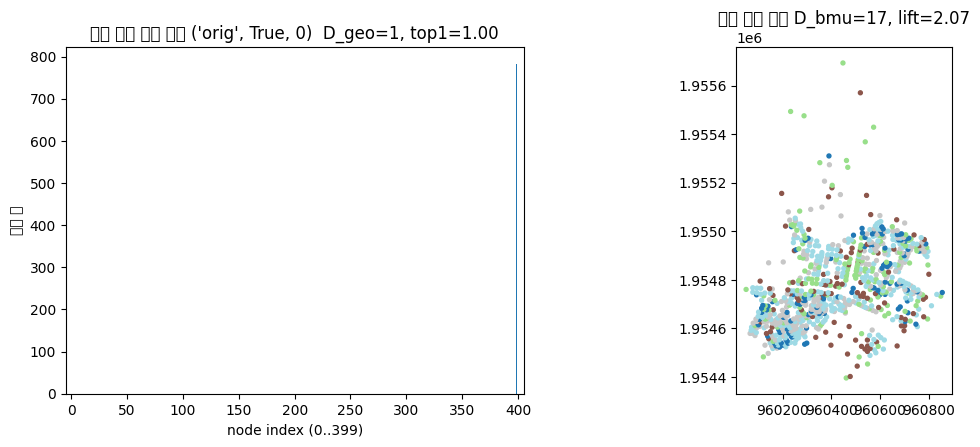

In [8]:
for s in (0, 1, 2): run_one('orig', True, s)
dfa = show([('orig', True, s) for s in (0, 1, 2)])
plot_run(('orig', True, 0))

## 4. 실험 (b): 수정본 (`fixed_geo=True`)
지리 가중치=데이터 좌표 bbox 격자, tolerance·반경=격자 거리. 시드 3개.

Training GeoSOMFixed: 100%|██████████| 50/50 [00:14<00:00,  3.39it/s]


,kind,fixed_geo,seed,N,D_geo,top1,top1_node,D_bmu,neigh_mean,knn_obs,knn_base,lift,판정
0,fixed,True,0,783,148,0.026,87,146,47.034,0.111,0.013,8.726,수정 성공
1,fixed,True,1,783,148,0.026,87,140,47.034,0.121,0.015,8.194,수정 성공
2,fixed,True,2,783,148,0.026,87,139,47.034,0.125,0.014,9.169,수정 성공


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44148 (\N{HANGUL SYLLABLE GEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47932 (\N{HANGUL SYLLABLE MUL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/lo

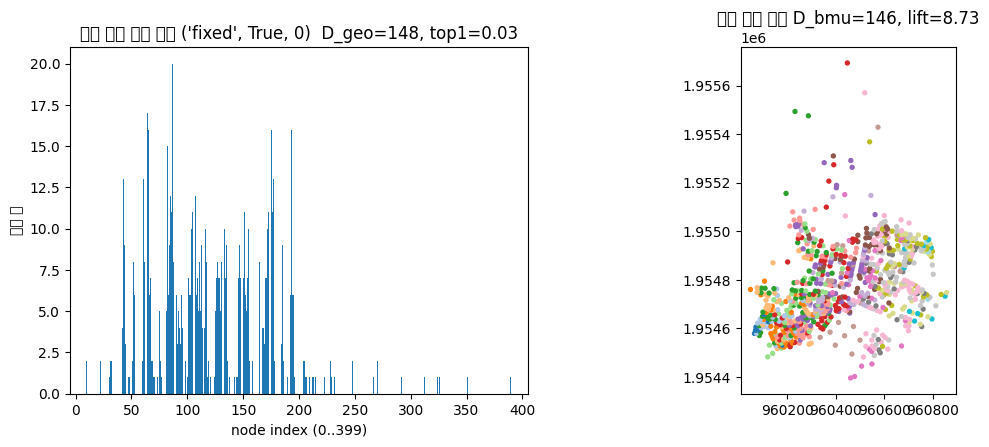

In [9]:
for s in (0, 1, 2): run_one('fixed', True, s)
dfb = show([('fixed', True, s) for s in (0, 1, 2)])
plot_run(('fixed', True, 0))

## 5. 실험 (c): `fixed_geo=False` (원본·수정본). [예측] 원본 False는 없음(관찰만)

Training GeoSOMFixed: 100%|██████████| 50/50 [00:14<00:00,  3.45it/s]


,kind,fixed_geo,seed,N,D_geo,top1,top1_node,D_bmu,neigh_mean,knn_obs,knn_base,lift,판정
0,orig,False,0,783,1,1.000,398,1,1.000,1.000,1.000,1.000,결함 재현
1,orig,False,1,783,1,1.000,397,1,1.000,1.000,1.000,1.000,결함 재현
2,orig,False,2,783,1,1.000,376,1,1.000,1.000,1.000,1.000,결함 재현
3,fixed,False,0,783,195,0.024,90,156,44.282,0.115,0.012,9.566,수정 성공
4,fixed,False,1,783,186,0.024,214,163,42.520,0.126,0.011,11.780,수정 성공
5,fixed,False,2,783,179,0.029,84,155,44.464,0.122,0.012,10.236,수정 성공


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44148 (\N{HANGUL SYLLABLE GEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47932 (\N{HANGUL SYLLABLE MUL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/lo

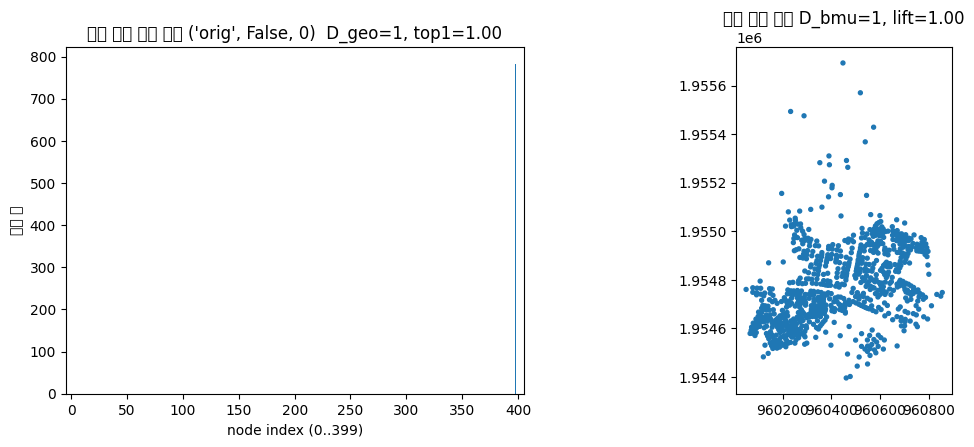

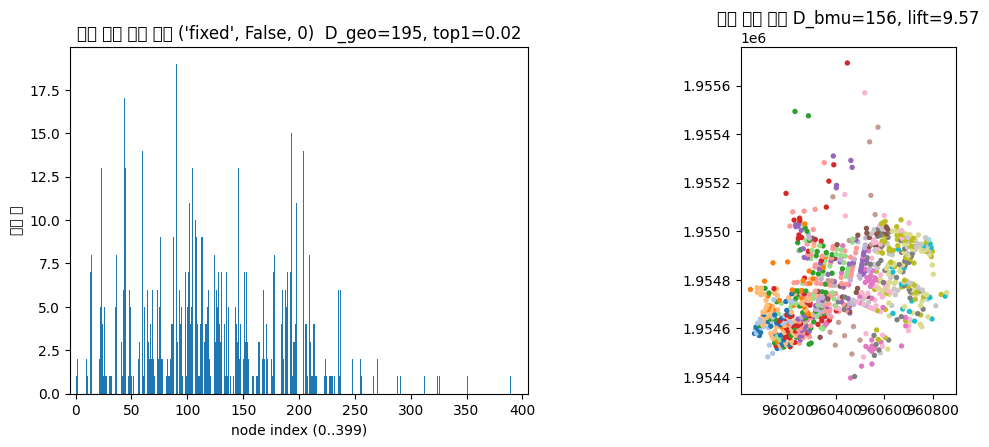

In [10]:
for s in (0, 1, 2): run_one('orig', False, s)
for s in (0, 1, 2): run_one('fixed', False, s)
dfc = show([(k, False, s) for k in ('orig', 'fixed') for s in (0, 1, 2)])
plot_run(('orig', False, 0)); plot_run(('fixed', False, 0))

In [11]:
# "fixed_geo가 차이를 만든다" 판정 (실행 전에 정한 기준 3장):
#   |D_geo의 False-True 평균 차이| > 시드 3개 범위(max-min, 두 쪽 중 큰 값)  그리고  (|dD_geo| >= 10 또는 |dlift| >= 0.3)
for kind in ('orig', 'fixed'):
    T = [RUNS[(kind, True, s)]['r'] for s in (0, 1, 2)]; F = [RUNS[(kind, False, s)]['r'] for s in (0, 1, 2)]
    dT, dF = [r['D_geo'] for r in T], [r['D_geo'] for r in F]
    dD = np.mean(dF) - np.mean(dT); dL = np.mean([r['lift'] for r in F]) - np.mean([r['lift'] for r in T])
    rng_ = max(max(dT) - min(dT), max(dF) - min(dF))
    diff = abs(dD) > rng_ and (abs(dD) >= 10 or abs(dL) >= 0.3)
    print(f"{kind}: dD_geo={dD:.1f}, dlift={dL:.2f}, 시드 범위={rng_} -> {'차이 있음' if diff else '이 규모에서는 차이를 확인하지 못함'}")

orig: dD_geo=0.0, dlift=-1.03, 시드 범위=0 -> 이 규모에서는 차이를 확인하지 못함
fixed: dD_geo=38.7, dlift=1.83, 시드 범위=16 -> 차이 있음


## 6. 실험 (d): `optimalK` maxClusters 15 vs 30 (각 5회)
입력 X = [x, y, x01, y01]: 원 노트북 셀 36~38과 같은 방식 (원본 (a) 시드 0 결과를 보로노이로 만들고 회기동 경계로 clip). 5회 × 2설정, 약 10분 안팎.

Xk (783, 4)
maxClusters=15 rep=0 -> k=11
maxClusters=15 rep=1 -> k=13
maxClusters=15 rep=2 -> k=12
maxClusters=15 rep=3 -> k=12
maxClusters=15 rep=4 -> k=14
maxClusters=30 rep=0 -> k=29
maxClusters=30 rep=1 -> k=26
maxClusters=30 rep=2 -> k=26
maxClusters=30 rep=3 -> k=29
maxClusters=30 rep=4 -> k=29
k(15): [11, 13, 12, 12, 14] | k(30): [29, 26, 26, 29, 29] | 중앙값 12.0 29.0 -> 경계 해 경향 재현


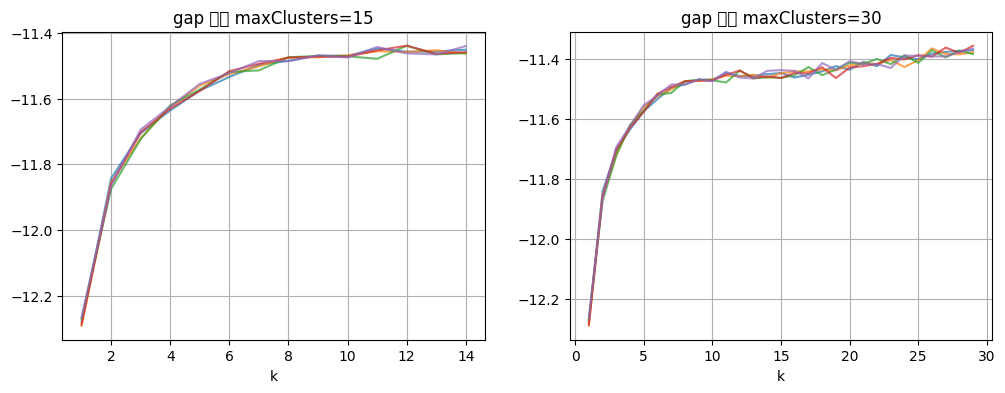

In [12]:
asg0 = RUNS[('orig', True, 0)]['asg']
polygons, vor = construct_voronoi_polygons(X_geo)
gdf_v = gpd.GeoDataFrame({'cluster': asg0}, geometry=polygons, crs='EPSG:5179')
gdf_v = gpd.clip(gdf_v, hoeGi_gdf)
for c in gdf_v['cluster'].unique():
    m_ = gdf_v['cluster'] == c
    gdf_v.loc[m_, 'x01'] = gdf_v[m_].geometry.centroid.x.mean()
    gdf_v.loc[m_, 'y01'] = gdf_v[m_].geometry.centroid.y.mean()
gdf_v['x'] = gdf_v.centroid.x; gdf_v['y'] = gdf_v.centroid.y
Xk = gdf_v[['x', 'y', 'x01', 'y01']].values
print('Xk', Xk.shape)

import warnings; warnings.filterwarnings('ignore')
KRES = {15: [], 30: []}
for mc in (15, 30):
    for rep in range(5):
        np.random.seed(rep)
        k, gdf_gap = optimalK(Xk, maxClusters=mc)
        KRES[mc].append((int(k), gdf_gap['gap'].tolist()))
        print(f'maxClusters={mc} rep={rep} -> k={k}')
ks15 = [k for k, _ in KRES[15]]; ks30 = [k for k, _ in KRES[30]]
if sum(k >= 25 for k in ks30) >= 3: v = '경계 해 경향 재현'
elif all(k < 14 for k in ks15) and all(k < 29 for k in ks30) and abs(np.median(ks15) - np.median(ks30)) <= 2: v = '내부 해, 안정'
else: v = '판정 보류'
print('k(15):', ks15, '| k(30):', ks30, '| 중앙값', np.median(ks15), np.median(ks30), '->', v)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, mc in zip(ax, (15, 30)):
    for k, g in KRES[mc]: a.plot(range(1, mc), g, alpha=.7)
    a.set_title(f'gap 곡선 maxClusters={mc}'); a.set_xlabel('k'); a.grid(True)
plt.show()

## 7. 저장

In [13]:
import json
out = dict(runs=[v['r'] for v in RUNS.values()], optimalK={str(k): v for k, v in KRES.items()}, verdict_d=v)
json.dump(out, open('/content/results.json', 'w'), ensure_ascii=False, indent=1)
from google.colab import files; files.download('/content/results.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>